# Practical 2: Feedforward Neural Network (MNIST)

Run the cells from top to bottom. Use ONE dataset loading option in Step 2.


In [1]:
# 1. Import packages (same as the reference notebook)
import tensorflow as tf
from tensorflow import keras
from keras.datasets import mnist
from keras import layers
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# 2. Load MNIST dataset - use ONE option

# OPTION 1: Directly from Keras (ACTIVE, same as reference)
# First run may download MNIST; future runs use the Keras cache.
(train_x, train_y), (test_x, test_y) = mnist.load_data()

# OPTION 2: MNIST .npz file in the same folder (OFFLINE)
# Comment Option 1 and uncomment all lines below.
# data = np.load("mnist.npz")
# train_x, train_y = data["x_train"], data["y_train"]
# test_x, test_y = data["x_test"], data["y_test"]

# OPTION 3: MNIST .csv files in the same folder (OFFLINE)
# Each CSV: first column = label, next 784 columns = pixel values.
# Comment Option 1 and uncomment all lines below.
# import pandas as pd
# train = pd.read_csv("mnist_train.csv")  # add header=None if no header row
# test = pd.read_csv("mnist_test.csv")    # add header=None if no header row
# train_y = train.iloc[:, 0].to_numpy()
# train_x = train.iloc[:, 1:].to_numpy().reshape(-1, 28, 28)
# test_y = test.iloc[:, 0].to_numpy()
# test_x = test.iloc[:, 1:].to_numpy().reshape(-1, 28, 28)

       0/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   16384/11490434 ━━━━━━━━━━━━━━━━━━━━ 2:12 12us/step

   32768/11490434 ━━━━━━━━━━━━━━━━━━━━ 1:33 8us/step 

   49152/11490434 ━━━━━━━━━━━━━━━━━━━━ 1:45 9us/step

   81920/11490434 ━━━━━━━━━━━━━━━━━━━━ 1:36 8us/step

  114688/11490434 ━━━━━━━━━━━━━━━━━━━━ 1:17 7us/step

... (29 outputs left out)

 9863168/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

10715136/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

11485184/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [3]:
# Step 3: Display dataset shapes
print("X_train:", train_x.shape)
print("Y_train:", train_y.shape)
print("X_test:", test_x.shape)
print("Y_test:", test_y.shape)


X_train: (60000, 28, 28)
Y_train: (60000,)
X_test: (10000, 28, 28)
Y_test: (10000,)


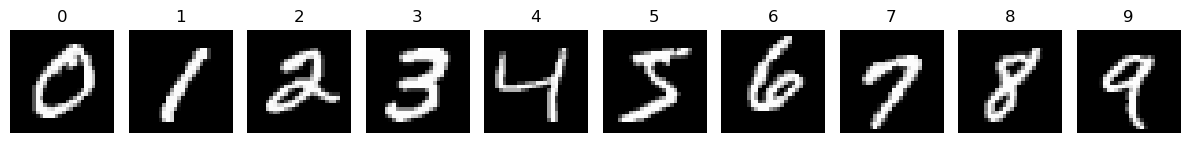

In [4]:
# Step 4: Display digits 0 to 9
plt.figure(figsize=(12, 3))
for digit in range(10):
    index = np.where(train_y == digit)[0][0]
    plt.subplot(1, 10, digit + 1)
    plt.imshow(train_x[index], cmap="gray")
    plt.title(str(digit))
    plt.axis("off")
plt.tight_layout()
plt.show()


In [5]:
# Step 5: Normalize images
train_x = train_x / 255.0
test_x = test_x / 255.0


In [6]:
# Step 6: Build the feedforward neural network
model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])


In [7]:
# Step 7: Compile using SGD optimizer
model.compile(optimizer="sgd", loss="sparse_categorical_crossentropy", metrics=["accuracy"])


In [8]:
# Step 8: Train model
history = model.fit(train_x, train_y, epochs=5, validation_split=0.1)


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8296 - loss: 0.6773 - val_accuracy: 0.9143 - val_loss: 0.3256
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9020 - loss: 0.3512 - val_accuracy: 0.9260 - val_loss: 0.2640
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9161 - loss: 0.2996 - val_accuracy: 0.9353 - val_loss: 0.2314
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9245 - loss: 0.2685 - val_accuracy: 0.9415 - val_loss: 0.2101
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9311 - loss: 0.2460 - val_accuracy: 0.9472 - val_loss: 0.1957


   1/1688 ━━━━━━━━━━━━━━━━━━━━ 33:24 1s/step - accuracy: 0.0625 - loss: 2.5003

  35/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2089 - loss: 2.2083  

  71/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.3517 - loss: 2.0545

 108/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.4398 - loss: 1.9288

 143/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.5035 - loss: 1.8196

... (370 outputs left out)

1645/1688 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9294 - loss: 0.2506

1662/1688 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9293 - loss: 0.2508

1680/1688 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9295 - loss: 0.2504

1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9296 - loss: 0.2503 - val_accuracy: 0.9450 - val_loss: 0.2000


In [9]:
# Step 9: Evaluate accuracy
loss, accuracy = model.evaluate(test_x, test_y)
print("Test Accuracy:", accuracy)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9342 - loss: 0.2269
Test Accuracy: 0.9341999888420105


 22/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9276 - loss: 0.2563  

 40/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9164 - loss: 0.2720

 60/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9115 - loss: 0.2933

 83/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9093 - loss: 0.3054

107/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9150 - loss: 0.2881

... (6 outputs left out)

272/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9329 - loss: 0.2370

295/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9363 - loss: 0.2258

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9347 - loss: 0.2303


Test Accuracy: 0.9347000122070312


Actual Digit: 7
Predicted Digit: 7


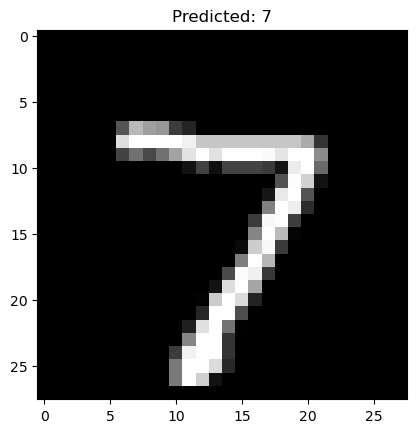

In [10]:
# Step 10: Predict and display one handwritten digit
prediction = model.predict(test_x[:1], verbose=0)
predicted_digit = np.argmax(prediction)
print("Actual Digit:", test_y[0])
print("Predicted Digit:", predicted_digit)
plt.imshow(test_x[0], cmap="gray")
plt.title(f"Predicted: {predicted_digit}")
plt.show()


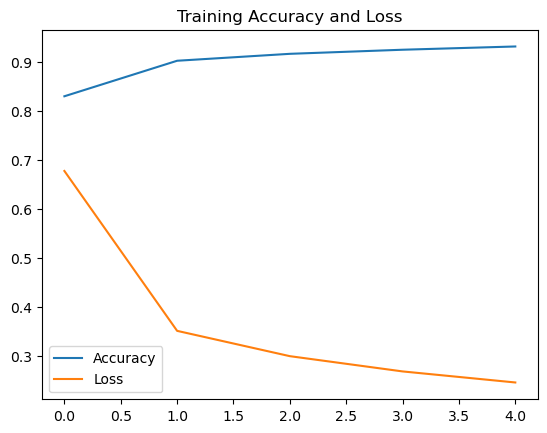

In [11]:
# Step 11: Plot training accuracy and loss
plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["loss"], label="Loss")
plt.legend()
plt.title("Training Accuracy and Loss")
plt.show()
